# mu-genome Wave-1 storage scaffold — test notebook

Branch `mu-genome`. Validates the per-cell agent mutation-rate gene
(`mu_lut_gene`) added as a **storage-only** scaffold (checkpoint §A / §I′ A2).

Scope of this Wave-1 change:
- One new SoA float array `mu_lut_gene[N*N]` in `C/evoca.c`.
- Initialised to the run's `mu_lut`.
- **Inherited** on reproduction (child copies parent's gene exactly).
- **Mutation of the gene is OFF**, and the gene is **read nowhere** that
  affects dynamics (the mutation draw still uses the global `mu_lut`).
- Python: `sim.get_mu_lut_gene()`, `sim.set_mu_lut_gene_all()`,
  `sim.set_mu_lut_gene(arr)` (distribution seeding for the later assay).

The three tests below assert:
1. **Default seeding** — the gene initialises to the run's `mu_lut`.
2. **Pure no-op** — seeding an arbitrary gene distribution leaves the
   dynamics (LUT-hash field + alive mask, every step) **bit-for-bit
   identical** to the default-gene run. I.e. genes-present-but-unused ==
   baseline.
3. **Inheritance** — with a seeded spatial gene distribution and
   reproduction on, the gene spreads into newly-born cells, and **no novel
   values appear** (gene is inherited, never mutated).

In [1]:
import os, sys, subprocess
import numpy as np

ROOT = os.getcwd()
while not os.path.exists(os.path.join(ROOT, 'C', 'evoca.h')):
    ROOT = os.path.dirname(ROOT)
SRC  = os.path.join(ROOT, 'C', 'evoca.c')
LIB  = os.path.join(ROOT, 'C', 'libevoca.dylib')
sys.path.insert(0, os.path.join(ROOT, 'python'))

# Build the library if missing or stale.
if (not os.path.exists(LIB)) or os.path.getmtime(LIB) < os.path.getmtime(SRC):
    subprocess.run(['gcc', '-O2', '-Wall', '-fPIC', '-dynamiclib',
                    '-o', LIB, SRC], cwd=ROOT, check=True)
    print('built', LIB)

from evoca_py import EvoCA
N = 64
results = {}
print('ready; N =', N)

ready; N = 64


In [2]:
def fresh_sim(mu_lut=0.01):
    """A reproducing halfplane config (mirrors evoca_explore.run_sim), with
    a fixed seed so runs are directly comparable. mutation of LUT/egene is
    left ON (mu_lut>0) to prove the gene is unused even when the global rate
    is nonzero; determinism is guaranteed by set_seed."""
    s = EvoCA(LIB)
    s.init(N, food_inc=0.013, m_scale=1.2, gdiff=0.06, tax=0.035,
           mu_lut=mu_lut, mu_egene=0.003, mu_egenome=0.005)
    s.set_seed(3)
    rng = np.random.default_rng(3)
    s.state(lut='gol', egenome='uniform', egenome_value=0b000011)
    s.set_v(rng.integers(0, 2, (N, N), dtype=np.uint8))
    s.set_f_all(0.5); s.set_F_all(1.0)
    s.set_alive_halfplane(0)
    return s

def trajectory(seed_gene=None, n_steps=300, sample_every=25):
    """Run and record (LUT-hash field, alive mask) at each sample step.
    Optionally seed the per-cell mu_lut_gene from an (N,N) array first."""
    s = fresh_sim()
    if seed_gene is not None:
        s.set_mu_lut_gene(seed_gene)
    hsh, alv = [], []
    for i in range(n_steps):
        s.step()
        if i % sample_every == 0:
            hsh.append(s.get_lut_hashes().copy())
            alv.append(s.get_alive().copy())
    final_gene = s.get_mu_lut_gene()
    final_alive = s.get_alive().reshape(N, N)
    s.free()
    return np.array(hsh), np.array(alv), final_gene, final_alive

print('helpers defined')

helpers defined


## Test 1 — default seeding: gene initialises to the run's `mu_lut`

In [3]:
s = fresh_sim(mu_lut=0.01)
gene0 = s.get_mu_lut_gene()
s.free()
uniq = np.unique(gene0)
ok1 = (uniq.size == 1) and np.isclose(uniq[0], 0.01, atol=1e-6)
results['default_seeding'] = bool(ok1)
print('unique gene values at init:', uniq)
print('shape:', gene0.shape, '(expected', (N, N), ')')
print('TEST 1', 'PASS' if ok1 else 'FAIL')

unique gene values at init: [0.01]
shape: (64, 64) (expected (64, 64) )
TEST 1 PASS


## Test 2 — pure no-op: seeded gene distribution == baseline dynamics

Run A: default gene (== `mu_lut`). Run B: a wild uniform-random gene field
over [0, 0.5]. Same seed. If the gene is truly read nowhere, the LUT-hash
field and the alive mask must be **identical at every sampled step**.

In [4]:
hA, aA, _, _ = trajectory(seed_gene=None)
rng = np.random.default_rng(999)
wild = rng.uniform(0.0, 0.5, (N, N)).astype(np.float32)
hB, aB, _, _ = trajectory(seed_gene=wild)

hashes_identical = np.array_equal(hA, hB)
alive_identical  = np.array_equal(aA, aB)
ok2 = hashes_identical and alive_identical
results['pure_noop'] = bool(ok2)
print('LUT-hash field identical across whole run:', hashes_identical)
print('alive mask identical across whole run:    ', alive_identical)
print('(sampled', hA.shape[0], 'timepoints over the run)')
print('TEST 2', 'PASS' if ok2 else 'FAIL',
      '— genes-present-but-unused == baseline')

LUT-hash field identical across whole run: True
alive mask identical across whole run:     True
(sampled 12 timepoints over the run)
TEST 2 PASS — genes-present-but-unused == baseline


## Test 3 — inheritance on reproduction (no mutation of the gene)

Seed a 3-band spatial gene distribution {0.02 | 0.09 | 0.15}, run with
reproduction, and check: (a) the gene spreads into newly-born cells
(inheritance actually happens), and (b) **no value outside the seeded set**
ever appears among live cells (the gene is copied, never mutated).

In [5]:
band = np.zeros((N, N), np.float32)
band[:, :N//3]        = 0.02
band[:, N//3:2*N//3]  = 0.09
band[:, 2*N//3:]      = 0.15

s = fresh_sim()
s.set_mu_lut_gene(band)
gene_seed = s.get_mu_lut_gene().copy()
births = 0
for i in range(300):
    s.step()
    births += int((s.get_births() > 0).sum())
gene_after = s.get_mu_lut_gene()
alive_after = s.get_alive().reshape(N, N)
s.free()

# Seeded set as float32 (compare in the array's own dtype to avoid repr noise).
seeded = np.unique(gene_seed.astype(np.float32))
present = np.unique(gene_after[alive_after == 1].astype(np.float32))
novel = np.setdiff1d(present, seeded)

changed_cells = int((gene_after != gene_seed).sum())
inheritance_happened = (births > 0) and (changed_cells > 0)
no_mutation = (novel.size == 0)
ok3 = inheritance_happened and no_mutation
results['inheritance'] = bool(ok3)
print('total births over run:      ', births)
print('cells whose gene changed:   ', changed_cells, '(inherited from a differing parent)')
print('seeded gene values:         ', seeded)
print('gene values among live cells:', present)
print('novel (mutated) values:     ', novel, '(must be empty)')
print('TEST 3', 'PASS' if ok3 else 'FAIL')

total births over run:       7700
cells whose gene changed:    2385 (inherited from a differing parent)
seeded gene values:          [0.02 0.09 0.15]
gene values among live cells: [0.02 0.09]
novel (mutated) values:      [] (must be empty)
TEST 3 PASS


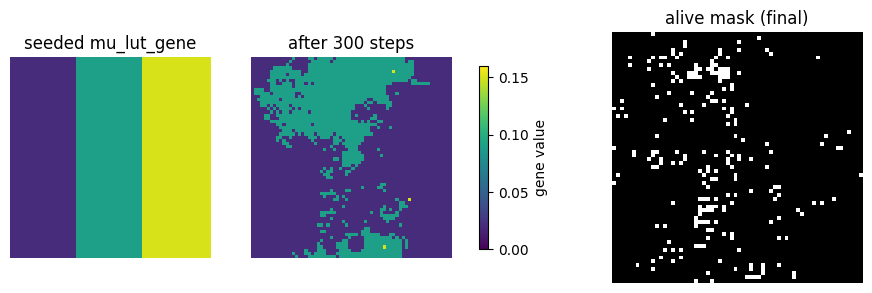

In [6]:
# Visualise the seeded vs post-run gene field (inheritance reshapes the bands).
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
    im0 = ax[0].imshow(gene_seed.reshape(N, N), cmap='viridis', vmin=0, vmax=0.16)
    ax[0].set_title('seeded mu_lut_gene')
    im1 = ax[1].imshow(gene_after.reshape(N, N), cmap='viridis', vmin=0, vmax=0.16)
    ax[1].set_title('after 300 steps')
    ax[2].imshow(alive_after, cmap='gray')
    ax[2].set_title('alive mask (final)')
    for a in ax: a.axis('off')
    fig.colorbar(im1, ax=ax[:2], shrink=0.7, label='gene value')
    plt.show()
except Exception as e:
    print('plot skipped:', e)

## Summary

In [7]:
all_pass = all(results.values())
for k, v in results.items():
    print(f'  {k:20s}: {"PASS" if v else "FAIL"}')
print('=' * 34)
print('OVERALL:', 'PASS' if all_pass else 'FAIL')
assert all_pass, 'mu-genome Wave-1 storage scaffold checks FAILED'

  default_seeding     : PASS
  pure_noop           : PASS
  inheritance         : PASS
OVERALL: PASS
